In [2]:
import os
os.chdir('/home/jiangwenbin/shared/workspace/AlphaCore/examples/voicebank')
print(os.getcwd())

/home/jiangwenbin/shared/workspace/AlphaCore/examples/voicebank


In [43]:
import shutil
from pathlib import Path
import librosa
import numpy as np
import librosa.display
import matplotlib.pyplot as plt
import torch

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# 全局字体配置（放在绘图代码最开头）
fontsize = 16
plt.rcParams.update({
    'font.family': 'serif',          # 衬线字体族（对应Times New Roman）
    'font.serif': ['Arial'],# 具体字体名称
    'axes.unicode_minus': False,     # 解决负号显示异常问题
    'xtick.labelsize': fontsize,     # x轴刻度字体大小
    'ytick.labelsize': fontsize,     # y轴刻度字体大小
    'axes.labelsize': fontsize,      # 坐标轴标签字体大小
    'legend.fontsize': fontsize - 2  # 图例字体大小（略小，层级清晰）
})

save_dir = Path('exp/paper/HomoGenSE')
save_dir.mkdir(parents=True, exist_ok=True)

In [ ]:
n_fft = 513
n_ceps = 27
_lifter = torch.zeros((n_fft))
_lifter[0: n_ceps+1] = 1
_lifter[(n_fft-n_ceps): n_fft] = 1
figsize = (9, 4)
linewidth = 2

chekpoint = torch.load('exp/logs/HomoSE/3a1/checkpoints/last.ckpt', map_location=torch.device("cpu"))
lifter = chekpoint['state_dict']['homo.lifter']

fig, ax = plt.subplots(figsize=figsize)
plt.plot(_lifter[:257], linewidth=linewidth, label='Traditional lifter')
plt.plot(torch.relu(lifter[:257]), linewidth=linewidth, label='Proposed lifter')
plt.legend()  # 显示图例区分两条线
plt.grid(True)
plt.savefig(save_dir/f"lifter_classic.pdf", dpi=250, bbox_inches='tight')
plt.show()

In [ ]:
n_fft = 513
n_ceps = 27
_lifter = torch.zeros((n_fft))
_lifter[0: n_ceps+1] = 1
_lifter[(n_fft-n_ceps): n_fft] = 1
figsize = (9, 4)
linewidth = 2

chekpoint = torch.load('exp/logs/HomoSE/3a1/checkpoints/last.ckpt', map_location=torch.device("cpu"))
lifter = chekpoint['state_dict']['homo.lifter']

fig, ax = plt.subplots(figsize=figsize)
ax.plot(_lifter[:257], linewidth=linewidth, label='Traditional lifter', 
        color='#2E86AB')
ax.plot(torch.relu(lifter[:257]), linewidth=linewidth, label='Proposed lifter', 
        color='#A23B72')
ax.grid(True, color='#E0E0E0', linestyle='--', linewidth=0.8, alpha=0.7)
ax.legend(loc='upper right', frameon=True, fancybox=False, edgecolor='#CCCCCC')
ax.set_xlabel('Quefrency Bin Index', labelpad=10)
ax.set_ylabel('Lifter Weight', labelpad=10)
ax.set_ylim(bottom=-0.02, top=max(_lifter[:257].max(), torch.relu(lifter[:257]).max()) * 1.1)
ax.set_xlim([-5,262])
plt.savefig(save_dir / "lifter.pdf", dpi=300, bbox_inches='tight', 
            facecolor='white', edgecolor='none')
plt.show()

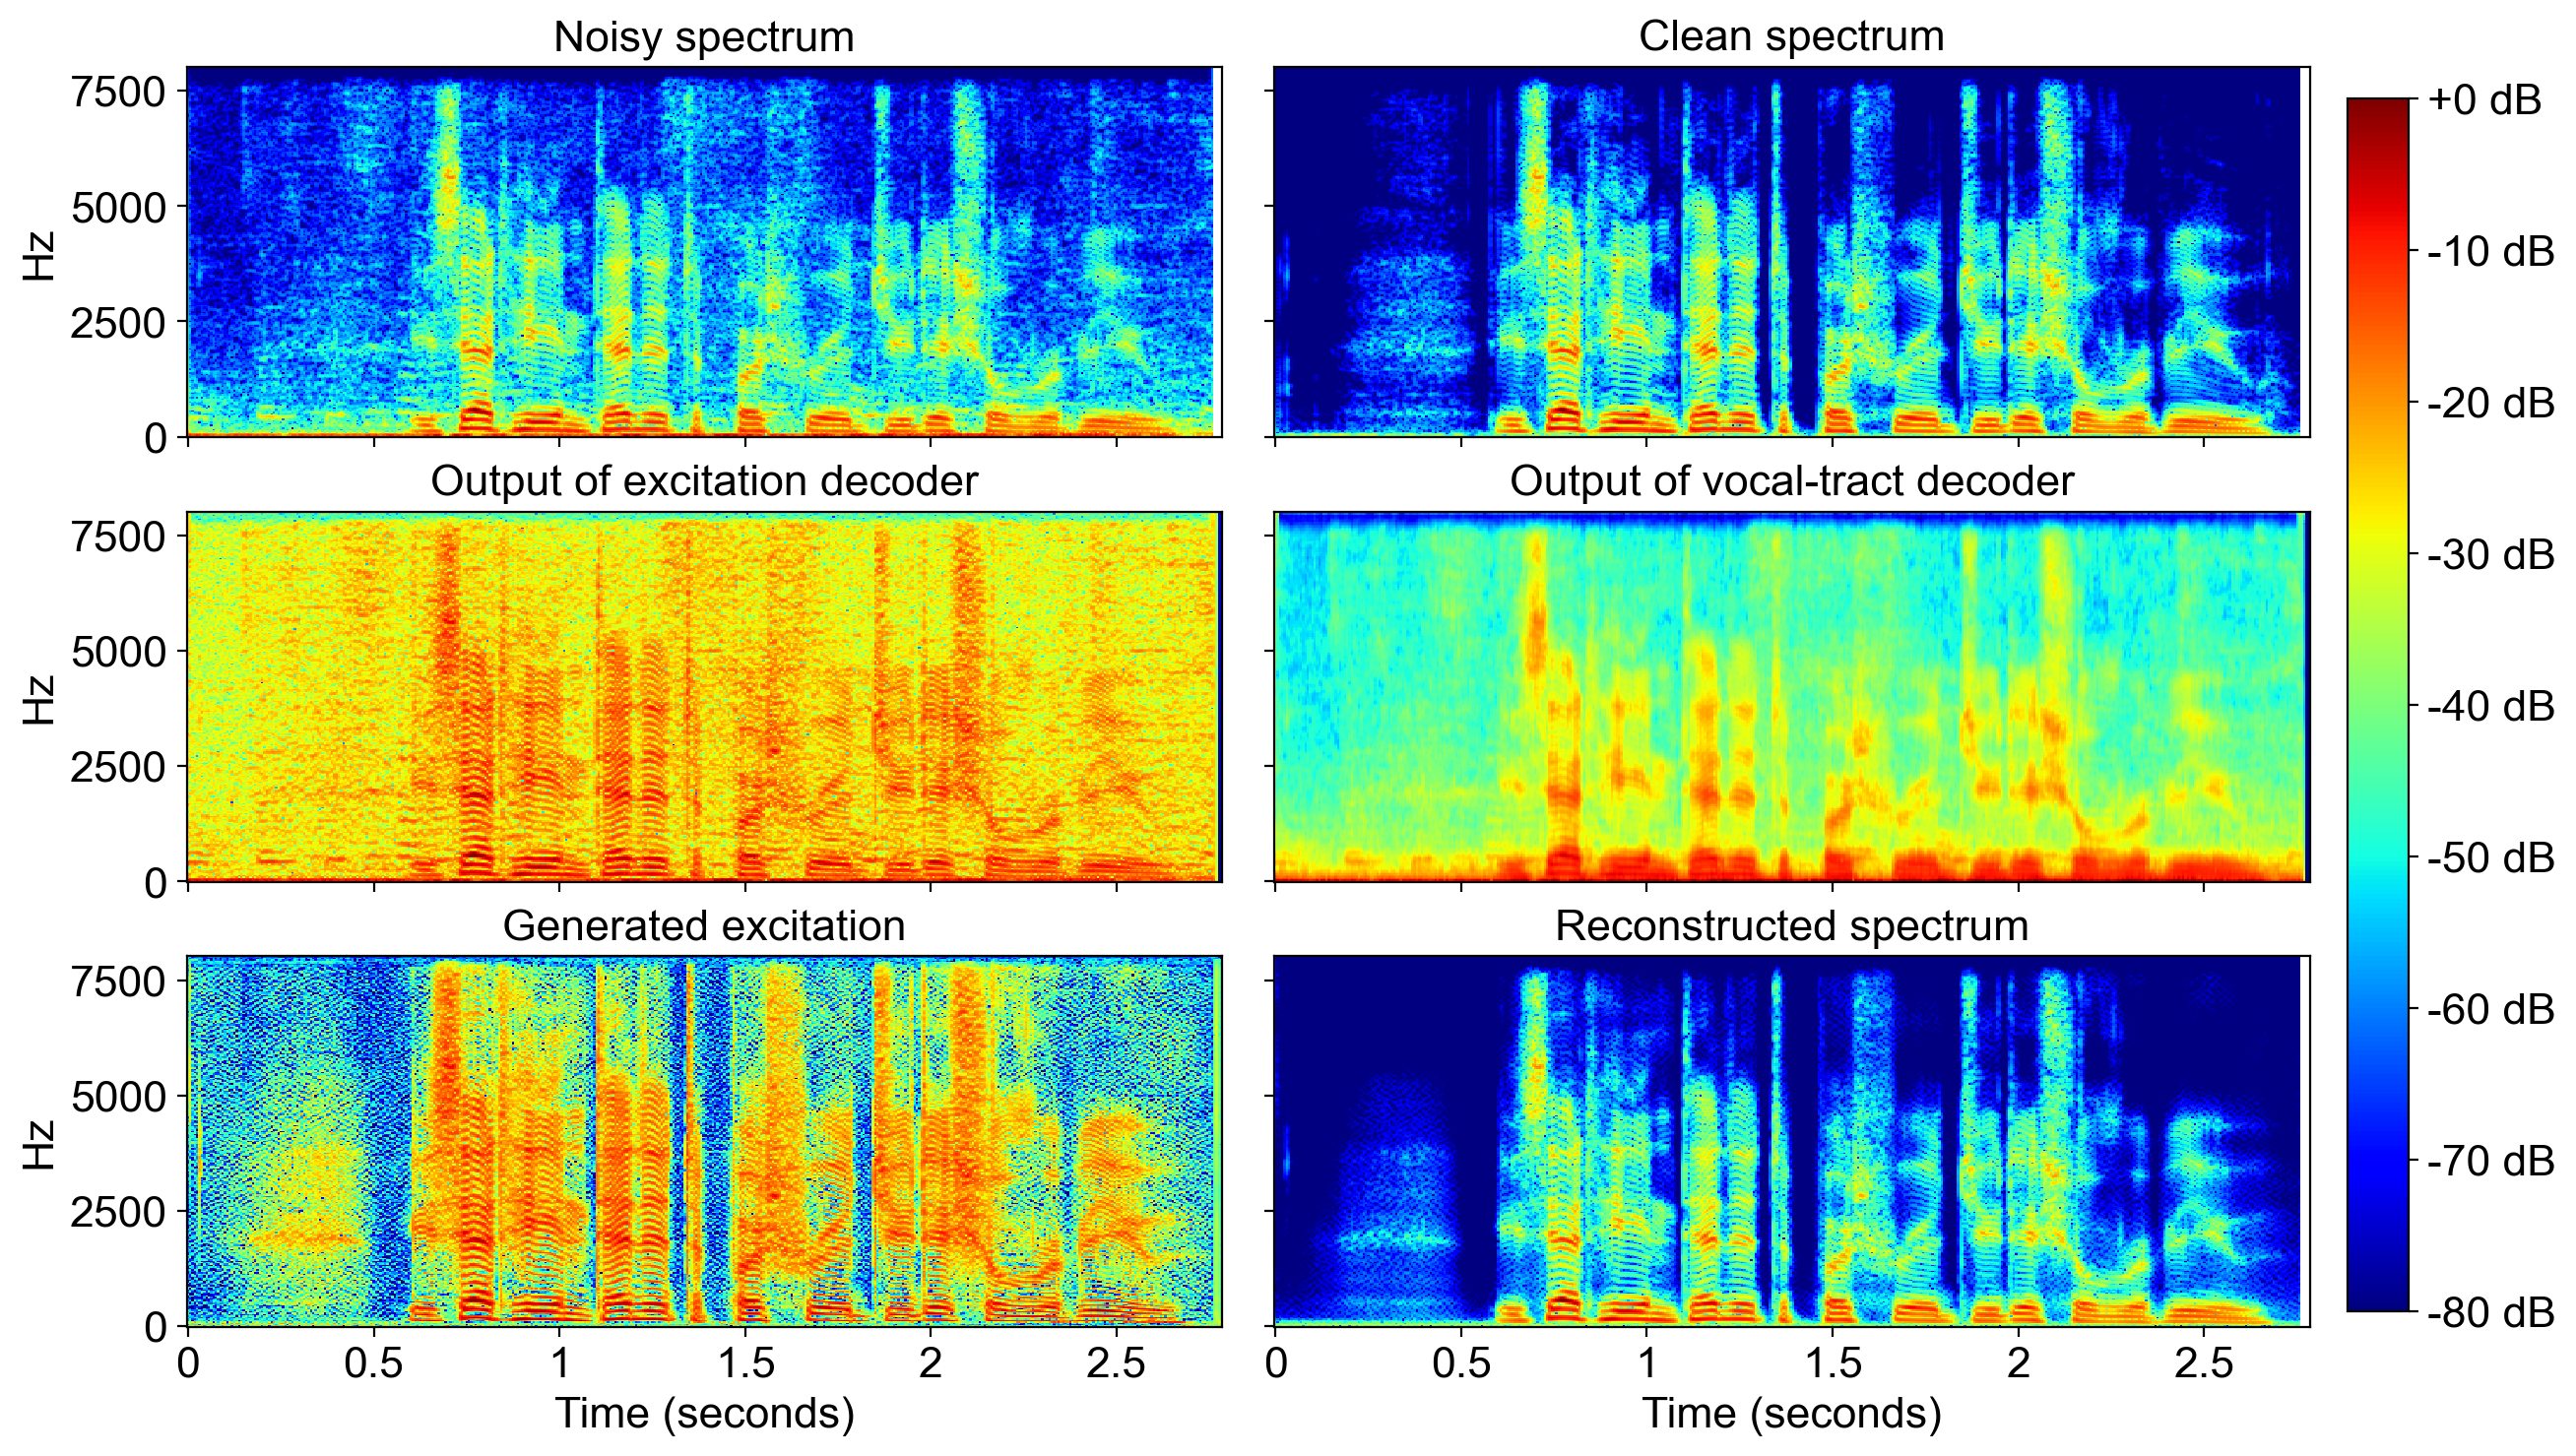

In [45]:
figsize = (18, 6)
nrows, ncols = 2, 3
sr = 16000
n_fft = 512
win_length=400
hop_length=100

plt.rcParams['font.sans-serif'] = ['simhei']

figsize = (14, 8)
nrows, ncols = 3, 2
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, sharex=True, figsize=figsize)

y, sr = librosa.load('exp/logs/UnSE/3a0e/clean/p232_258.wav', sr=None)
stft_y = librosa.stft(y, n_fft=n_fft, win_length=win_length, hop_length=hop_length)
clean_D = librosa.amplitude_to_db(np.abs(stft_y), ref=np.max)

y, sr = librosa.load('exp/logs/UnSE/3a0e/noisy/p232_258.wav', sr=None)
stft_y = librosa.stft(y, n_fft=n_fft, win_length=win_length, hop_length=hop_length)
noisy_D = librosa.amplitude_to_db(np.abs(stft_y), ref=np.max)

y, sr = librosa.load('exp/logs/HomoGenSE/3a2d/est/p232_258.wav', sr=None)
stft_y = librosa.stft(y, n_fft=n_fft, win_length=win_length, hop_length=hop_length)
est_D = librosa.amplitude_to_db(np.abs(stft_y), ref=np.max)


data_list = [
    (noisy_D, 'Noisy spectrum'),
    (clean_D, 'Clean spectrum'),
    (librosa.amplitude_to_db(np.abs(np.load("exp/debug/npy/est_excit.npy").squeeze()), ref=np.max), 'Output of excitation decoder'),
    (librosa.amplitude_to_db(np.abs(np.load("exp/debug/npy/est_vocal.npy").squeeze()), ref=np.max), 'Output of vocal-tract decoder'),
    (librosa.amplitude_to_db(np.abs(np.load("exp/debug/npy/gen_excit.npy").squeeze()), ref=np.max), 'Generated excitation'),
    # (librosa.amplitude_to_db(np.abs(np.load("exp/debug/npy/gen_spec.npy").squeeze()), ref=np.max), 'Generated spectrum'),
    (est_D, 'Reconstructed spectrum')
]

for idx, (D, title) in enumerate(data_list):
    row_idx, col_idx = idx//ncols, idx%ncols
    img = librosa.display.specshow(D, y_axis='linear', x_axis='s', sr=sr, hop_length=hop_length,
                                   ax=ax[row_idx, col_idx], cmap=('jet'))   
    ax[row_idx, col_idx].set_title(title, fontsize=fontsize)

for ax_i in ax:
    for ax_ij in ax_i:
        ax_ij.label_outer()
fig.colorbar(img, ax=ax, format="%+2.f dB")
fig.subplots_adjust(left=0,bottom=0.1,top=0.9,right=0.77,hspace=0.2,wspace=0.05)
fig.savefig(save_dir / "components.png", dpi=120, bbox_inches='tight')
plt.show()

In [23]:
data_list[5][0].shape

(1, 1, 257, 446)